# Why Do Medical Expenditures Concentrate Among a Small Share of Individuals?

This EDA examines the extent of concentration, characteristics of people in the
top expenditure allocation, and the services and payers that make up their
spending. The comparisons describe associations, not causal effects.
Definitions and sources are in the [analysis plan](../analysis_plan.md).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE_DIR = Path.cwd().parent
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from analysis import (load_data, analyze, export_results, lorenz, weighted_quantile,
                      top_fraction, concentration, sha256, RAW)
raw_frame, raw_hash = load_data()
sample, summary, tables = analyze(raw_frame)
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

Matplotlib is building the font cache; this may take a moment.


## Sample and validation

Use positive annual person weights. No negative or missing expenditures are
recoded to zero. Original data are not changed; a selected-column cache is stored
locally. Each positive-weight person stays in the distribution, including zero
spenders and people in scope for part of the year. Component checks allow the
small differences caused by separately rounded dollar amounts.

In [2]:
pd.Series({k: summary[k] for k in ["raw_n", "positive_weight_n", "zero_weight_n",
    "represented_population", "total_spending"]}, name="Sample and represented totals")

raw_n                               18,919.0000
positive_weight_n                   18,463.0000
zero_weight_n                          456.0000
represented_population         334,530,273.1680
total_spending           2,504,715,663,922.5664
Name: Sample and represented totals, dtype: float64

In [3]:
pd.DataFrame({
    "max_person_abs_difference_USD": summary["component_max_abs_difference"],
    "weighted_total_difference_USD": summary["component_weighted_difference"],
})

,max_person_abs_difference_USD,weighted_total_difference_USD
services,0.0000,0.0000
payers,4.0000,"5,793,184.7193"


## Mean, typical spending, and the zero-spending share

The weighted mean describes spending per person; the median and upper quantiles
show where people lie in the distribution. The mean's 95% interval uses Taylor
linearization with MEPS strata and PSUs. Other metrics are point estimates.
Unweighted summaries refer to the same positive-weight records and are shown
only to illustrate the effect of weighting.

In [4]:
pd.Series({k:summary[k] for k in ["mean","se","ci_low","ci_high","design_df",
    "median","p90","p95","p99","zero_share","gini","unweighted_mean","unweighted_median"]})

mean                 7,487.2616
se                     173.3692
ci_low               7,144.8246
ci_high              7,829.6986
design_df              157.0000
median               1,583.0000
p90                 18,330.0000
p95                 34,150.0000
p99                 93,443.0000
zero_share               0.1445
gini                     0.7805
unweighted_mean      8,535.6644
unweighted_median    1,879.0000
dtype: float64

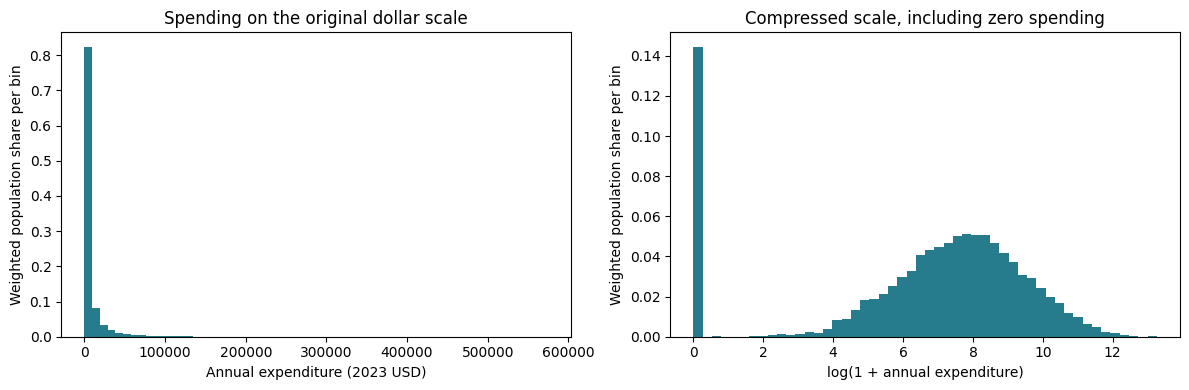

In [5]:
y = sample.TOTEXP23.to_numpy()
w = sample.PERWT23F.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(y, bins=60, weights=w/w.sum(), color="#267b8d")
axes[0].set(xlabel="Annual expenditure (2023 USD)", ylabel="Weighted population share per bin",
            title="Spending on the original dollar scale")
axes[1].hist(np.log1p(y), bins=50, weights=w/w.sum(), color="#267b8d")
axes[1].set(xlabel="log(1 + annual expenditure)", ylabel="Weighted population share per bin",
            title="Compressed scale, including zero spending")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"distribution.png", dpi=160)
plt.show()

## How concentrated is spending?

Top groups contain exactly the stated fraction of weighted population. At a
boundary tie, tied observations receive the same fractional inclusion. This is
an accounting allocation, not a literal subset or clinical label. The Lorenz
curve uses cumulative weighted population and spending; a long right tail does
not establish a mathematical heavy-tail distribution.

In [6]:
display(tables["concentration"])
pd.Series({"bottom50_spending_share":summary["bottom50_share"],
           "weighted_top5_spending_share":summary["top5_share"],
           "unweighted_top5_spending_share":summary["unweighted_top5_share"]})

,population_fraction,spending_share
0,0.0100,0.2009
1,0.0500,0.4867
2,0.1000,0.6523
3,0.5000,0.9711


bottom50_spending_share          0.0289
weighted_top5_spending_share     0.4867
unweighted_top5_spending_share   0.4687
dtype: float64

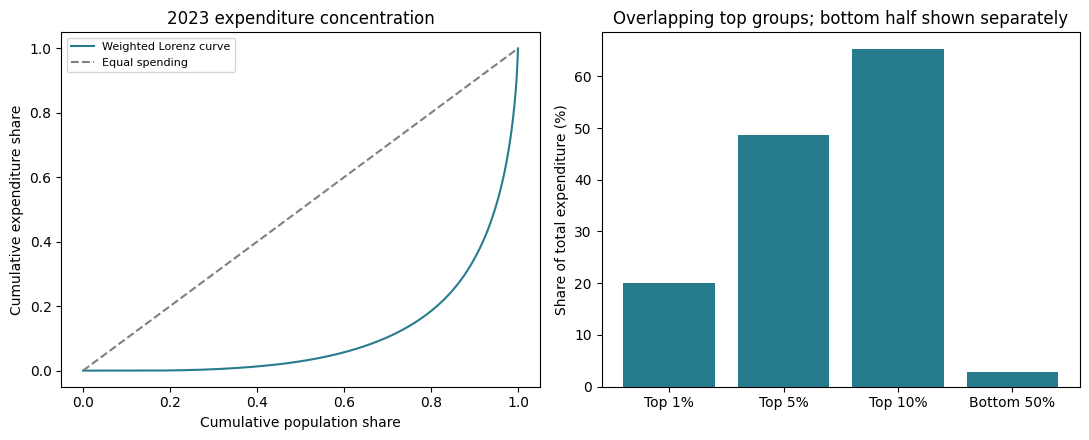

In [7]:
population, spending = lorenz(y, w)
fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
axes[0].plot(population, spending, color="#267b8d", label="Weighted Lorenz curve")
axes[0].plot([0,1],[0,1],"--",color="gray",label="Equal spending")
axes[0].set(xlabel="Cumulative population share",ylabel="Cumulative expenditure share",
            title="2023 expenditure concentration")
axes[0].legend(fontsize=8)
axes[1].bar(["Top 1%","Top 5%","Top 10%","Bottom 50%"],
             [summary[k]*100 for k in ["top1_share","top5_share","top10_share","bottom50_share"]],color="#267b8d")
axes[1].set(ylabel="Share of total expenditure (%)",title="Overlapping top groups; bottom half shown separately")
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"concentration.png", dpi=160)
plt.show()

## Which characteristics are associated with high expenditure?

Each table compares the entire weighted population with the top 5% allocation.
`population_share` is a group's share of all people; `top5_population_share` is
its share of the top allocation. `spending_share` is its share of total spending,
not its share within the top group. Group means and medians describe all people
in that group. `n` is the unweighted subgroup count.

Age uses `AGE23X`, poverty uses `POVCAT23`, health uses reported status in Round
3/1 (`RTHLTH31`), and inpatient utilization uses `IPDIS23`. Unknown/inapplicable
codes are retained in labeled categories. Health may change during the year;
inpatient stays occur during the spending period. These comparisons do not
separate age, health, income, or utilization effects, and have no confidence
intervals or significance tests.

In [8]:
for name in ["age", "health", "poverty", "inpatient"]:
    print(name.upper())
    display(tables[name])

AGE


,group,n,population_share,top5_population_share,mean,median,spending_share
0,0–17,3554,0.2161,0.0571,"2,934.6417",729.0000,0.0847
1,18–44,5522,0.3537,0.1456,"4,519.5447",877.0000,0.2135
2,45–64,4742,0.2434,0.3565,"9,759.0510","2,559.0000",0.3173
3,65+,4504,0.1791,0.3989,"14,989.5658","5,711.0000",0.3586
4,Unknown,141,0.0077,0.0418,"25,295.9437","5,718.0000",0.0259


HEALTH


,group,n,population_share,top5_population_share,mean,median,spending_share
0,Excellent,4947,0.2950,0.0680,"3,174.7923",807.0000,0.1251
1,Fair,1956,0.0897,0.2450,"16,880.5212","5,088.0000",0.2022
2,Good,5105,0.2650,0.3181,"8,478.4126","2,124.0000",0.3000
3,Missing/inapplicable,186,0.0130,0.0271,"9,901.7688","1,088.0000",0.0172
4,Poor,554,0.0245,0.1171,"30,019.3925","12,608.0000",0.0982
5,Very good,5715,0.3129,0.2247,"6,158.5408","1,641.0000",0.2574


POVERTY


,group,n,population_share,top5_population_share,mean,median,spending_share
0,Below poverty,2803,0.1109,0.1143,"7,005.4888",757.0000,0.1037
1,High income,7226,0.4427,0.4938,"8,357.5295","2,229.0000",0.4941
2,Low income,2421,0.1210,0.1050,"6,233.8936",941.0000,0.1007
3,Middle income,5145,0.2873,0.2446,"6,865.1759","1,302.0000",0.2635
4,Near poor,868,0.0381,0.0422,"7,449.3241",892.0000,0.0379


INPATIENT


,group,n,population_share,top5_population_share,mean,median,spending_share
0,Any inpatient stay,1380,0.0643,0.5559,"43,142.7138","28,960.0000",0.3708
1,No inpatient stay,17083,0.9357,0.4441,"5,035.2950","1,318.0000",0.6292


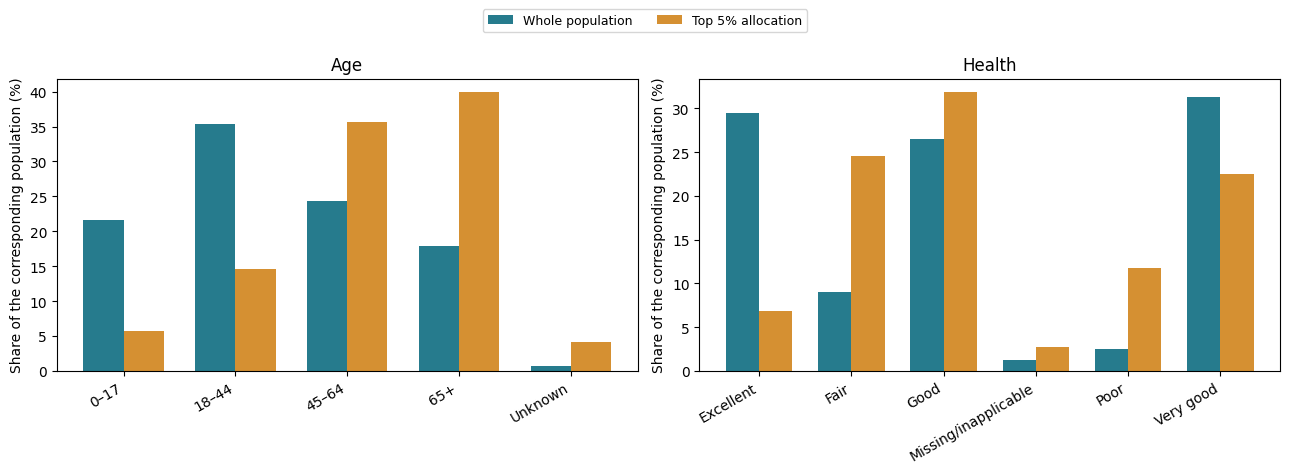

In [9]:
fig, axes = plt.subplots(1,2,figsize=(13,4.8))
for ax,name in zip(axes,["age","health"]):
    table=tables[name]
    positions=np.arange(len(table))
    ax.bar(positions-.18,table.population_share*100,.36,label="Whole population",color="#267b8d")
    ax.bar(positions+.18,table.top5_population_share*100,.36,label="Top 5% allocation",color="#d59032")
    ax.set_xticks(positions,table.group,rotation=30,ha="right")
    ax.set(ylabel="Share of the corresponding population (%)",title=name.capitalize())
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(.5,.99), fontsize=9)
fig.tight_layout(rect=(0,0,1,.91))
fig.savefig(OUTPUT_DIR/"characteristics.png",dpi=160)
plt.show()

## Which services and payers make up spending?

Service categories and payment sources are separate decompositions of the same
dollars. Facility/physician subtotals and collapsed payer categories are excluded
to avoid double-counting. Each column divides component expenditure by the
corresponding overall or top-5% expenditure total. Rounding differences are
reported above rather than forced to zero. No prices, medical need, or causal
effects can be recovered from this accounting breakdown alone.

In [10]:
display(tables["services"])
display(tables["payers"])

,component,overall_share,top5_share
0,Office-based,0.2520,0.1574
1,Outpatient,0.1139,0.1124
2,Emergency,0.0355,0.0226
3,Inpatient,0.2221,0.3594
4,Prescriptions,0.2273,0.2555
5,Dental,0.0604,0.0131
6,Home health agency,0.0407,0.0538
7,Home health independent,0.0037,0.0035
8,Vision,0.0117,0.0015
9,Other supplies/equipment,0.0328,0.0209


,component,overall_share,top5_share
0,Out of pocket,0.1337,0.0701
1,Medicare,0.2784,0.3398
2,Medicaid,0.1111,0.0942
3,Private,0.4210,0.4347
4,VA/CHAMPVA,0.0240,0.0293
5,TRICARE,0.0135,0.0151
6,Other federal,0.0020,0.0018
7,State/local,0.0043,0.0042
8,Workers compensation,0.0040,0.0014
9,Other unclassified,0.0081,0.0095


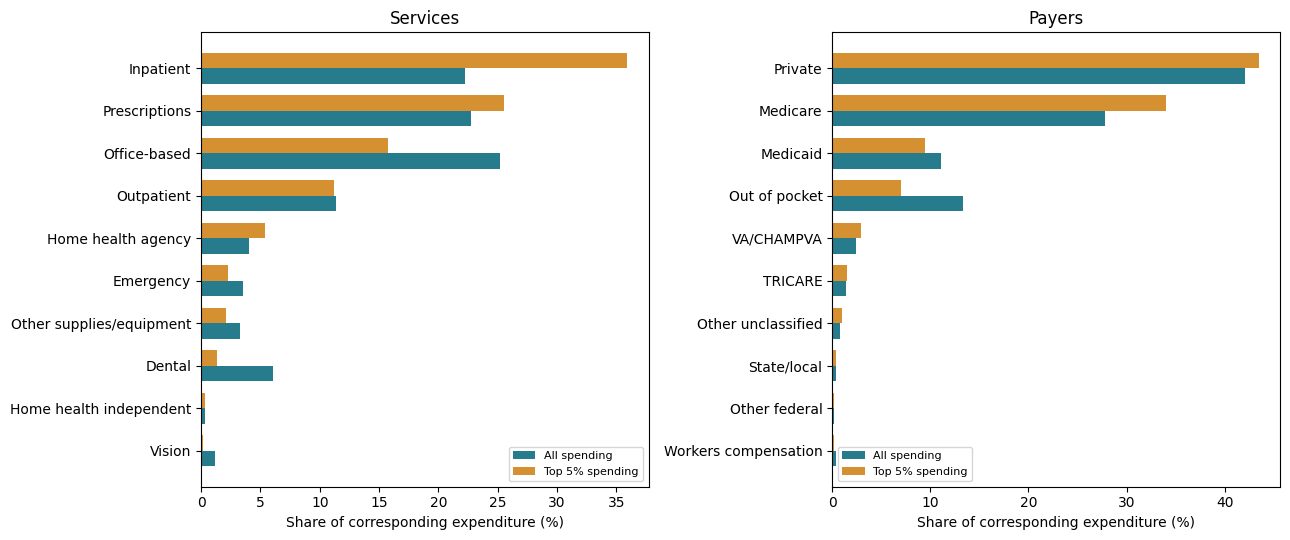

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
for ax,name in zip(axes,["services","payers"]):
    table=tables[name].sort_values("top5_share")
    positions=np.arange(len(table))
    ax.barh(positions-.18,table.overall_share*100,.36,label="All spending",color="#267b8d")
    ax.barh(positions+.18,table.top5_share*100,.36,label="Top 5% spending",color="#d59032")
    ax.set_yticks(positions,table.component)
    ax.set(xlabel="Share of corresponding expenditure (%)",title=name.capitalize())
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"composition.png",dpi=160)
plt.show()

## Interpretation and reproducibility

Read the [EDA summary](../eda_summary.md) for the observed results.
The decompositions describe spending concentration. They do not identify
the causes of illness or care use. The mean remains relevant to aggregate
costs even when it differs greatly from the median. Subgroup estimates and
concentration shares are descriptive; only the overall mean has design-based
sampling uncertainty. Partial-year exposure, reported/imputed expenditures,
health-status timing, and the excluded institutionalized population limit
interpretation. No predictive or causal model is fitted.

In [12]:
assert sha256(RAW) == raw_hash, "Raw workbook changed"
assert len(raw_frame) == 18919 and len(sample) == 18463
assert np.isclose(sample.PERWT23F.sum(),334530273,atol=.5,rtol=0)
assert np.isclose(np.dot(w,top_fraction(y,w,.05)),.05*w.sum())
assert 0 <= summary["top1_share"] <= summary["top5_share"] <= summary["top10_share"] <= 1
assert np.isclose(np.dot(tables["age"].population_share,tables["age"]["mean"]),summary["mean"])
export_results(summary,tables,raw_hash)
print("Validated source hash, official sample counts, population weights, concentration and subgroup reconciliation.")

Validated source hash, official sample counts, population weights, concentration and subgroup reconciliation.
